# ML Capstone: Fraud Detection

In [12]:
# Imports
import argparse
import json
import sys
import time
import warnings
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    average_precision_score,
    classification_report,
    confusion_matrix,
    f1_score,
    precision_recall_curve,
    precision_score,
    recall_score,
    roc_auc_score,
    roc_curve,
)
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.tree import DecisionTreeClassifier

warnings.filterwarnings("ignore")
RANDOM_STATE = 42

In [18]:
# Config and project folders
# __file__ is undefined in interactive cells, so fall back to the current folder.
try:
    BASE_DIR = Path(__file__).resolve().parent
except NameError:
    BASE_DIR = Path.cwd()


def get_args():
    p = argparse.ArgumentParser()
    p.add_argument("--data", default=str(BASE_DIR / "data" / "paysim.csv"),
                   help="Path to the PaySim CSV")
    p.add_argument("--train-legit-cap", type=int, default=1_000_000,
                   help="Max legitimate rows used for TRAINING (all fraud kept). "
                        "0 = use everything. Test set is never reduced.")
    p.add_argument("--show-plots", action="store_true", help="Open plot windows")
    # parse_known_args so VS Code / Jupyter extra args don't crash it
    return p.parse_known_args()[0]


args = get_args()
DATA_PATH = Path(args.data)
TRAIN_LEGIT_CAP = args.train_legit_cap

for folder in ["data", "models", "results", "plots"]:
    (BASE_DIR / folder).mkdir(parents=True, exist_ok=True)
MODELS_DIR, RESULTS_DIR, PLOTS_DIR = (BASE_DIR / f for f in ("models", "results", "plots"))

if not args.show_plots:
    plt.switch_backend("Agg") if "ipykernel" not in sys.modules else None


def finish_plot(name):
    plt.tight_layout()
    plt.savefig(PLOTS_DIR / f"{name}.png", dpi=120)
    if args.show_plots or "ipykernel" in sys.modules:
        plt.show()
    plt.close()

In [14]:
# Load data
import pandas as pd

df = pd.read_csv("../data/onlinefraud.csv")

print("Shape:", df.shape)
print("Missing values:", int(df.isnull().sum().sum()), "| Duplicates:", int(df.duplicated().sum()))
print(df["isFraud"].value_counts())

Shape: (6362620, 11)
Missing values: 0 | Duplicates: 0
isFraud
0    6354407
1       8213
Name: count, dtype: int64


            count   sum    rate_%
type                             
CASH_IN   1399284     0  0.000000
CASH_OUT  2237500  4116  0.183955
DEBIT       41432     0  0.000000
PAYMENT   2151495     0  0.000000
TRANSFER   532909  4097  0.768799


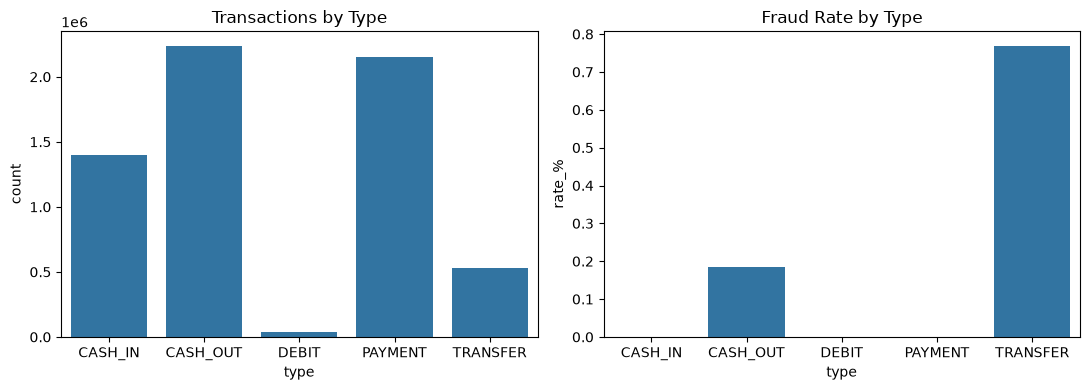

In [4]:
# Quick EDA
t = df.groupby("type")["isFraud"].agg(["count", "sum"])
t["rate_%"] = t["sum"] / t["count"] * 100
print(t)

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
sns.countplot(x="type", data=df, order=t.index, ax=ax[0])
ax[0].set_title("Transactions by Type")
sns.barplot(x=t.index, y=t["rate_%"], ax=ax[1])
ax[1].set_title("Fraud Rate by Type")
finish_plot("eda_type")

In [17]:
# Feature engineering
class FraudFeatureEngineer(BaseEstimator, TransformerMixin):
    REQUIRED = ["step", "type", "amount", "oldbalanceOrg", "newbalanceOrig",
                "oldbalanceDest", "newbalanceDest", "nameDest"]

    def fit(self, X, y=None):
        missing = [c for c in self.REQUIRED if c not in X.columns]
        if missing:
            raise ValueError(f"Missing columns: {missing}")
        return self

    def transform(self, X):
        d = pd.DataFrame(index=X.index)
        amt = X["amount"].astype(float)
        d["step"] = X["step"].astype(float)
        d["amount"] = amt
        for c in ["oldbalanceOrg", "newbalanceOrig", "oldbalanceDest", "newbalanceDest"]:
            d[c] = X[c].astype(float)
        d["hour"] = (X["step"] % 24).astype(float)
        d["day"] = (X["step"] // 24).astype(float)
        d["errorBalanceOrig"] = d["newbalanceOrig"] + amt - d["oldbalanceOrg"]
        d["errorBalanceDest"] = d["oldbalanceDest"] + amt - d["newbalanceDest"]
        d["orig_emptied"] = (d["newbalanceOrig"] == 0).astype(float)
        d["dest_is_merchant"] = X["nameDest"].astype(str).str.startswith("M").astype(float)
        d["dest_balance_zero_before"] = (d["oldbalanceDest"] == 0).astype(float)
        d["amount_to_orig_balance"] = amt / (d["oldbalanceOrg"] + 1)
        d["log_amount"] = np.log1p(amt)
        d["type"] = X["type"].astype(str)
        return d


RAW_FEATURES = FraudFeatureEngineer.REQUIRED
X = df[RAW_FEATURES].copy()
y = df["isFraud"].astype(int)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=RANDOM_STATE
)

# Optional: cap legitimate rows in training so tree/forest models fit in reasonable time
if TRAIN_LEGIT_CAP and (y_train == 0).sum() > TRAIN_LEGIT_CAP:
    keep_legit = y_train[y_train == 0].sample(TRAIN_LEGIT_CAP, random_state=RANDOM_STATE).index
    keep = y_train[y_train == 1].index.union(keep_legit)
    X_train, y_train = X_train.loc[keep], y_train.loc[keep]

print("Train:", X_train.shape, y_train.value_counts().to_dict())
print("Test :", X_test.shape, y_test.value_counts().to_dict())

Train: (1006570, 8) {0: 1000000, 1: 6570}
Test : (1272524, 8) {0: 1270881, 1: 1643}


In [6]:
# Preprocessing
numeric_features = [
    "step", "amount", "oldbalanceOrg", "newbalanceOrig", "oldbalanceDest",
    "newbalanceDest", "hour", "day", "errorBalanceOrig", "errorBalanceDest",
    "orig_emptied", "dest_is_merchant", "dest_balance_zero_before",
    "amount_to_orig_balance", "log_amount",
]
categorical_features = ["type"]


def make_preprocessor():
    return ColumnTransformer([
        ("num", Pipeline([("imputer", SimpleImputer(strategy="median")),
                          ("scaler", StandardScaler())]), numeric_features),
        ("cat", Pipeline([("imputer", SimpleImputer(strategy="most_frequent")),
                          ("encoder", OneHotEncoder(handle_unknown="ignore", sparse_output=False))]),
         categorical_features),
    ])

In [7]:
# Models and pipelines
models = {
    "Logistic Regression": LogisticRegression(
        max_iter=300, class_weight="balanced", random_state=RANDOM_STATE),
    "Decision Tree": DecisionTreeClassifier(
        max_depth=12, min_samples_leaf=10, class_weight="balanced", random_state=RANDOM_STATE),
    "Random Forest": RandomForestClassifier(
        n_estimators=100, max_depth=12, min_samples_leaf=5, class_weight="balanced",
        n_jobs=-1, random_state=RANDOM_STATE),
    "HistGradientBoosting": HistGradientBoostingClassifier(
        class_weight="balanced", random_state=RANDOM_STATE),
}

pipelines = {
    name: Pipeline([("features", FraudFeatureEngineer()),
                    ("preprocessor", make_preprocessor()),
                    ("model", model)])
    for name, model in models.items()
}

In [8]:
# FIT the models and evaluate
trained_models, rows = {}, []

for name, pipe in pipelines.items():
    print(f"Fitting {name} ...", end=" ", flush=True)
    t0 = time.time()
    pipe.fit(X_train, y_train)          # <-- model fitting
    fit_s = time.time() - t0
    print(f"{fit_s:.1f}s")

    y_pred = pipe.predict(X_test)
    y_prob = pipe.predict_proba(X_test)[:, 1]
    trained_models[name] = pipe

    rows.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred, zero_division=0),
        "Recall": recall_score(y_test, y_pred, zero_division=0),
        "F1": f1_score(y_test, y_pred, zero_division=0),
        "ROC_AUC": roc_auc_score(y_test, y_prob),
        "PR_AUC": average_precision_score(y_test, y_prob),
        "Fit_seconds": fit_s,
    })

# Rank by PR-AUC: the right headline metric for heavily imbalanced fraud data
results_df = pd.DataFrame(rows).sort_values("PR_AUC", ascending=False).reset_index(drop=True)
print(results_df.round(4).to_string(index=False))
results_df.to_csv(RESULTS_DIR / "model_comparison.csv", index=False)

Fitting Logistic Regression ... 11.3s
Fitting Decision Tree ... 41.1s
Fitting Random Forest ... 97.7s
Fitting HistGradientBoosting ... 31.4s
               Model  Accuracy  Precision  Recall     F1  ROC_AUC  PR_AUC  Fit_seconds
HistGradientBoosting    0.9999     0.9540  0.9976 0.9753   1.0000  0.9987      31.3572
       Random Forest    1.0000     0.9721  0.9976 0.9847   0.9999  0.9987      97.7453
       Decision Tree    0.9998     0.8604  0.9976 0.9239   0.9988  0.9970      41.0912
 Logistic Regression    0.9699     0.0401  0.9720 0.0770   0.9961  0.6212      11.3333


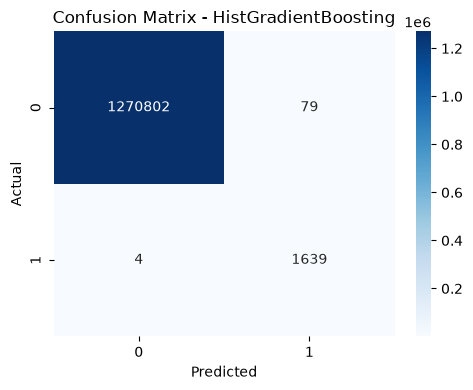

              precision    recall  f1-score   support

           0     1.0000    0.9999    1.0000   1270881
           1     0.9540    0.9976    0.9753      1643

    accuracy                         0.9999   1272524
   macro avg     0.9770    0.9988    0.9876   1272524
weighted avg     0.9999    0.9999    0.9999   1272524



In [9]:
# Best model: confusion matrix + report
best_name = results_df.iloc[0]["Model"]
best_model = trained_models[best_name]
y_pred = best_model.predict(X_test)

plt.figure(figsize=(5, 4))
sns.heatmap(confusion_matrix(y_test, y_pred), annot=True, fmt="d", cmap="Blues")
plt.xlabel("Predicted"); plt.ylabel("Actual"); plt.title(f"Confusion Matrix - {best_name}")
finish_plot("confusion_matrix")
print(classification_report(y_test, y_pred, digits=4))

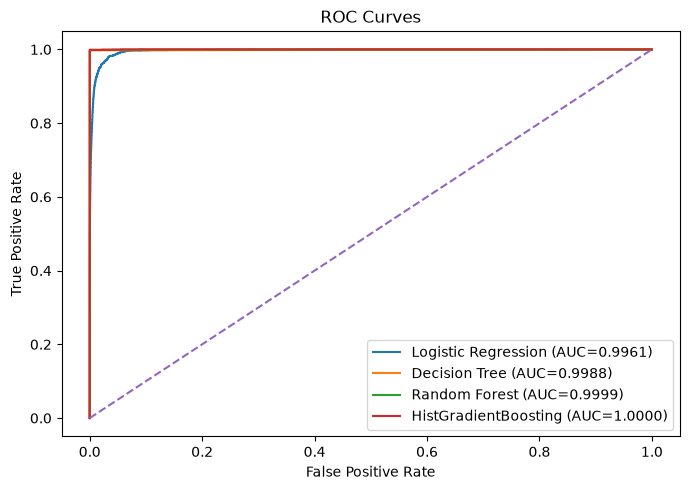

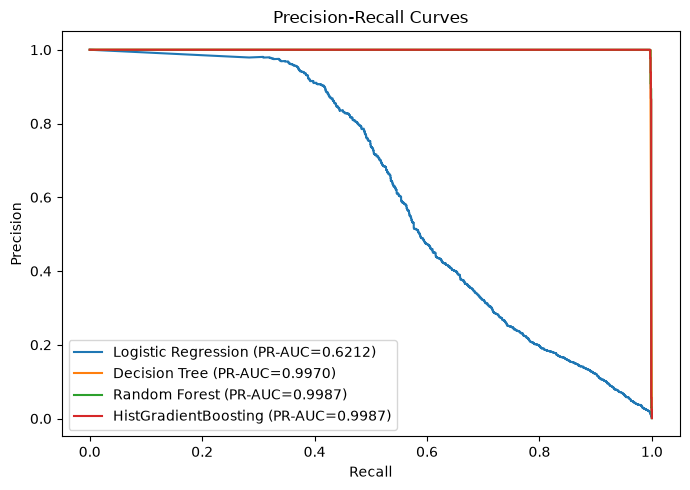

In [10]:
# ROC and Precision-Recall curves
probs = {n: m.predict_proba(X_test)[:, 1] for n, m in trained_models.items()}

plt.figure(figsize=(7, 5))
for n, p in probs.items():
    fpr, tpr, _ = roc_curve(y_test, p)
    plt.plot(fpr, tpr, label=f"{n} (AUC={roc_auc_score(y_test, p):.4f})")
plt.plot([0, 1], [0, 1], "--")
plt.xlabel("False Positive Rate"); plt.ylabel("True Positive Rate")
plt.title("ROC Curves"); plt.legend()
finish_plot("roc_curves")

plt.figure(figsize=(7, 5))
for n, p in probs.items():
    prec, rec, _ = precision_recall_curve(y_test, p)
    plt.plot(rec, prec, label=f"{n} (PR-AUC={average_precision_score(y_test, p):.4f})")
plt.xlabel("Recall"); plt.ylabel("Precision")
plt.title("Precision-Recall Curves"); plt.legend()
finish_plot("pr_curves")

In [11]:
# Save model + metrics, verify reload
BEST_MODEL_PATH = MODELS_DIR / "best_model.pkl"
joblib.dump(best_model, BEST_MODEL_PATH)

loaded = joblib.load(BEST_MODEL_PATH)
print("Reloaded predictions identical:", np.array_equal(y_pred, loaded.predict(X_test)))

with open(RESULTS_DIR / "metrics.json", "w") as f:
    json.dump(results_df.iloc[0].to_dict(), f, indent=4)
print("Saved to:", BASE_DIR)

Reloaded predictions identical: True
Saved to: c:\Users\Hitasha.Padhi\Downloads\online-fraud-detection-mlops\notebooks
